In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

In [3]:
# load the dataset
df = pd.read_csv("Adm.csv")
print(df.head())
# check rows and columns
print("dataset shape:", df.shape)
# check column names and data types
print(df.info())

# check missing values
print(df.isnull().sum())
# check duplicate rows
print("duplicate rows:", df.duplicated().sum())
# check the admission chance
print(df["Chance of Admit"].describe())

   Serial No.  GRE Score  TOEFL Score  University Rating  SOP  LOR  CGPA  \
0           1        337          118                  4  4.5  4.5  9.65   
1           2        324          107                  4  4.0  4.5  8.87   
2           3        316          104                  3  3.0  3.5  8.00   
3           4        322          110                  3  3.5  2.5  8.67   
4           5        314          103                  2  2.0  3.0  8.21   

   Research  Chance of Admit Application_DateTime  \
0         1             0.92  2022-01-01 09:00:00   
1         1             0.76  2022-01-02 09:00:00   
2         1             0.72  2022-01-04 09:00:00   
3         1             0.80  2022-01-06 09:00:00   
4         0             0.65  2022-01-08 09:00:00   

                              University_Name region  
0    Indian Institute of Technology Kharagpur   East  
1  National Institute of Technology Karnataka  South  
2                          Gujarat University   West  
3   

admission_status
1    594
0    406
Name: count, dtype: int64
admission_status
1    59.4
0    40.6
Name: proportion, dtype: float64


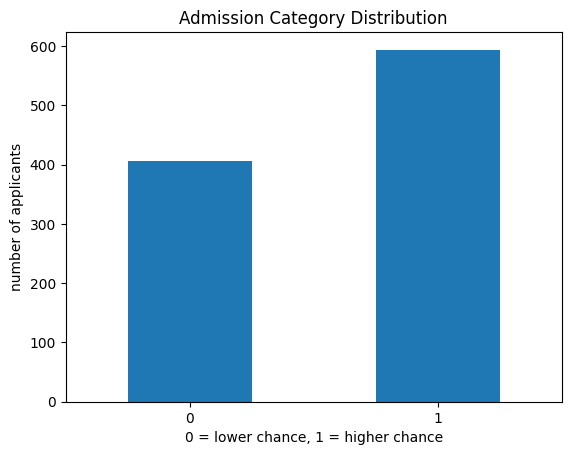

In [4]:
# remove duplicate rows
df = df.drop_duplicates().copy()
# remove rows where the target is missing
df = df.dropna(subset=["Chance of Admit"])

# create the binary admission target
df["admission_status"] = (
    df["Chance of Admit"] >= 0.70
).astype(int)
# check the number of records in each class
print(df["admission_status"].value_counts())

# check the percentage of each class
print(df["admission_status"].value_counts(normalize=True) * 100)
# display the target distribution
df["admission_status"].value_counts().sort_index().plot(
    kind="bar"
)

plt.title("Admission Category Distribution")
plt.xlabel("0 = lower chance, 1 = higher chance")
plt.ylabel("number of applicants")
plt.xticks(rotation=0)
plt.show()

In [5]:
# select the input features
features = [
    "GRE Score",
    "TOEFL Score",
    "University Rating",
    "SOP",
    "LOR",
    "CGPA",
    "Research"
]

# create the input and target data
x = df[features]
y = df["admission_status"]

# split into training and testing data
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("training records:", x_train.shape[0])
print("testing records:", x_test.shape[0])

training records: 800
testing records: 200


In [6]:
# create the logistic regression pipeline
basic_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(
        penalty="l2",
        C=1.0,
        max_iter=5000,
        random_state=42
    ))
])

# train the model
basic_model.fit(x_train, y_train)

# make predictions
y_pred = basic_model.predict(x_test)

# evaluate the basic model
print("accuracy:", accuracy_score(y_test, y_pred))
print("precision:", precision_score(y_test, y_pred, zero_division=0))
print("recall:", recall_score(y_test, y_pred, zero_division=0))
print("f1 score:", f1_score(y_test, y_pred, zero_division=0))
print("roc auc:", roc_auc_score(
    y_test,
    basic_model.predict_proba(x_test)[:, 1]
))

accuracy: 0.655
precision: 0.6923076923076923
recall: 0.7563025210084033
f1 score: 0.7228915662650602
roc auc: 0.715219421101774


In [7]:
# create models using l1 and l2 regularization
l1_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(
        penalty="l1",
        solver="liblinear",
        C=1.0,
        max_iter=5000,
        random_state=42
    ))
])

l2_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(
        penalty="l2",
        solver="liblinear",
        C=1.0,
        max_iter=5000,
        random_state=42
    ))
])

# train both models
l1_model.fit(x_train, y_train)
l2_model.fit(x_train, y_train)

# compare the test results
for name, model in [
    ("l1 regularization", l1_model),
    ("l2 regularization", l2_model)
]:
    pred = model.predict(x_test)
    prob = model.predict_proba(x_test)[:, 1]

    print("\n", name)
    print("accuracy:", round(accuracy_score(y_test, pred), 3))
    print("precision:", round(precision_score(
        y_test, pred, zero_division=0
    ), 3))
    print("recall:", round(recall_score(
        y_test, pred, zero_division=0
    ), 3))
    print("f1 score:", round(f1_score(
        y_test, pred, zero_division=0
    ), 3))
    print("roc auc:", round(roc_auc_score(y_test, prob), 3))


 l1 regularization
accuracy: 0.65
precision: 0.69
recall: 0.748
f1 score: 0.718
roc auc: 0.715

 l2 regularization
accuracy: 0.655
precision: 0.692
recall: 0.756
f1 score: 0.723
roc auc: 0.715


                   GRE Score  TOEFL Score  University Rating   SOP   LOR  \
GRE Score               1.00         0.22               0.19  0.27  0.19   
TOEFL Score             0.22         1.00               0.19  0.19  0.18   
University Rating       0.19         0.19               1.00  0.30  0.28   
SOP                     0.27         0.19               0.30  1.00  0.32   
LOR                     0.19         0.18               0.28  0.32  1.00   
CGPA                    0.27         0.24               0.27  0.25  0.32   
Research                0.17         0.16               0.20  0.17  0.17   

                   CGPA  Research  
GRE Score          0.27      0.17  
TOEFL Score        0.24      0.16  
University Rating  0.27      0.20  
SOP                0.25      0.17  
LOR                0.32      0.17  
CGPA               1.00      0.26  
Research           0.26      1.00  


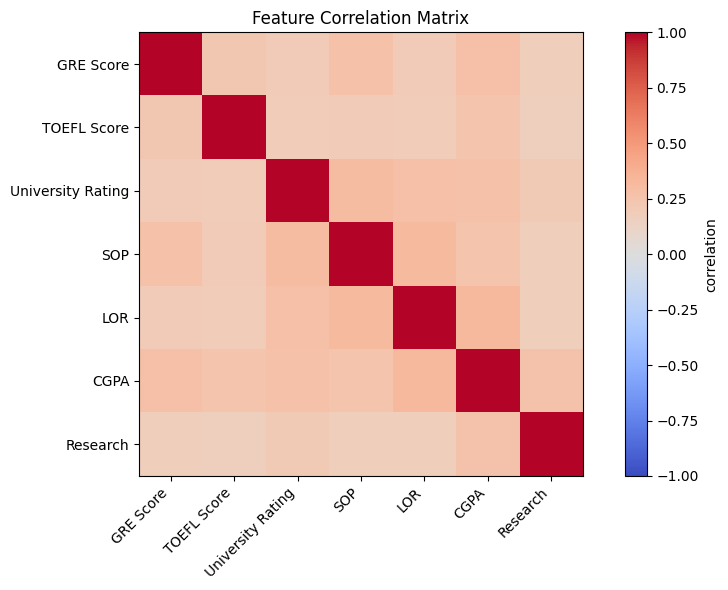

In [8]:
# calculate correlations between input features
corr = x_train.corr()

# display the correlation matrix
print(corr.round(2))

# visualize the correlations
plt.figure(figsize=(9, 6))

plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="correlation")

plt.xticks(
    range(len(corr.columns)),
    corr.columns,
    rotation=45,
    ha="right"
)

plt.yticks(range(len(corr.columns)), corr.columns)
plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

In [10]:
# calculate vif for each feature
from statsmodels.stats.outliers_influence import variance_inflation_factor

# fill missing values before calculating vif
vif_data = x_train.copy()
vif_data = vif_data.fillna(vif_data.median())

# standardize the features
vif_scaled = pd.DataFrame(
    StandardScaler().fit_transform(vif_data),
    columns=vif_data.columns
)

# calculate vif scores
vif_results = pd.DataFrame({
    "feature": vif_scaled.columns,
    "vif": [variance_inflation_factor(vif_scaled.values, i)
        for i in range(vif_scaled.shape[1])]
})

# display the results
print(vif_results.sort_values(
    "vif", ascending=False
).round(2))

             feature   vif
5               CGPA  1.28
3                SOP  1.24
4                LOR  1.24
2  University Rating  1.21
0          GRE Score  1.17
1        TOEFL Score  1.12
6           Research  1.11


In [11]:
# create the pipeline for tuning
tune_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(
        solver="liblinear",
        max_iter=5000,
        random_state=42
    ))
])

# define the parameter values to test
params = [
    {
        "logistic__penalty": ["l1"],
        "logistic__C": [0.001, 0.01, 0.1, 1, 10, 100]
    },
    {
        "logistic__penalty": ["l2"],
        "logistic__C": [0.001, 0.01, 0.1, 1, 10, 100]
    }
]

# search for the best combination
grid = GridSearchCV(
    tune_model,
    params,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

# train and tune using the training data
grid.fit(x_train, y_train)

# select the best model
best_model = grid.best_estimator_

print("best parameters:", grid.best_params_)
print("best cross-validation f1:", round(grid.best_score_, 3))

best parameters: {'logistic__C': 10, 'logistic__penalty': 'l1'}
best cross-validation f1: 0.724


In [13]:
# make final predictions
final_pred = best_model.predict(x_test)

# calculate predicted probabilities
final_prob = best_model.predict_proba(x_test)[:, 1]

# display evaluation metrics
print("accuracy:", round(accuracy_score(y_test, final_pred), 3))
print("precision:", round(precision_score(
    y_test, final_pred, zero_division=0
), 3))
print("recall:", round(recall_score(
    y_test, final_pred, zero_division=0
), 3))
print("f1 score:", round(f1_score(
    y_test, final_pred, zero_division=0
), 3))
print("roc auc:", round(roc_auc_score(y_test, final_prob), 3))

# display the detailed classification report
print(classification_report(
    y_test,
    final_pred,
    target_names=["lower chance", "higher chance"],
    zero_division=0
))

accuracy: 0.655
precision: 0.692
recall: 0.756
f1 score: 0.723
roc auc: 0.715
               precision    recall  f1-score   support

 lower chance       0.59      0.51      0.54        81
higher chance       0.69      0.76      0.72       119

     accuracy                           0.66       200
    macro avg       0.64      0.63      0.63       200
 weighted avg       0.65      0.66      0.65       200



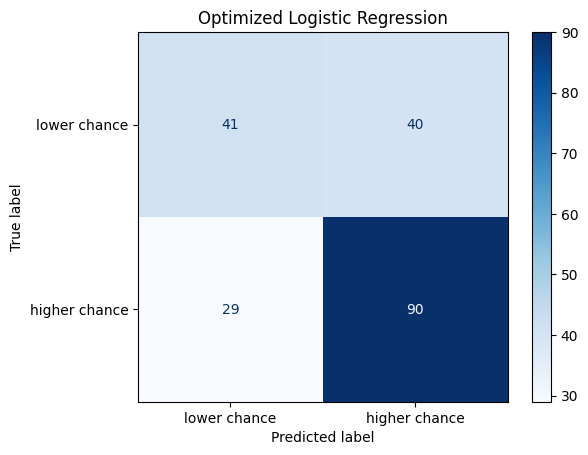

In [14]:
# create the confusion matrix
cm = confusion_matrix(y_test, final_pred)

# display the confusion matrix
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["lower chance", "higher chance"]
)

display.plot(cmap="Blues")
plt.title("Optimized Logistic Regression")
plt.show()

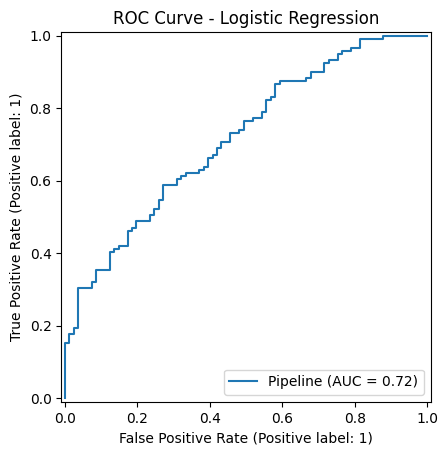

In [15]:
# display the roc curve
RocCurveDisplay.from_estimator(
    best_model,
    x_test,
    y_test
)

plt.title("ROC Curve - Logistic Regression")
plt.show()

          feature  coefficient
             CGPA       0.3998
        GRE Score       0.3367
         Research       0.2284
      TOEFL Score       0.2094
              LOR       0.1404
              SOP       0.1188
University Rating       0.0299


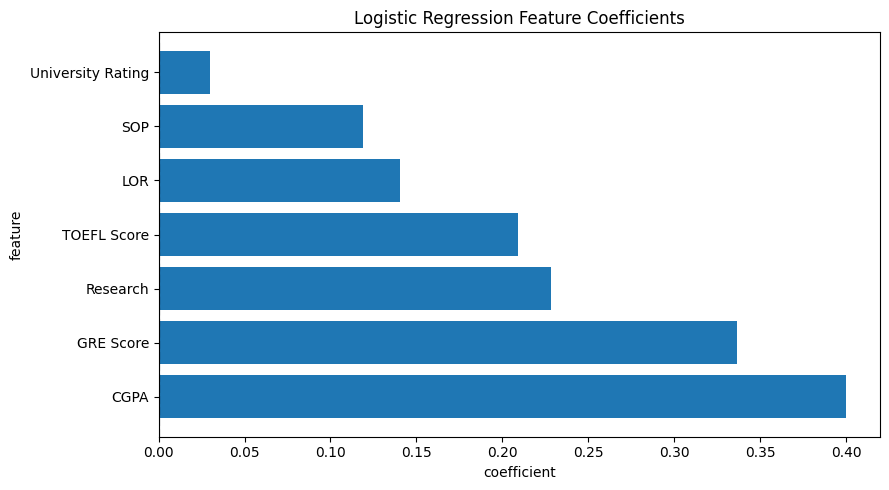

In [16]:
# get the trained logistic regression model
log_model = best_model.named_steps["logistic"]

# get the feature coefficients
coef_df = pd.DataFrame({
    "feature": x_train.columns,
    "coefficient": log_model.coef_[0]
})

# sort by coefficient
coef_df = coef_df.sort_values(
    "coefficient",
    ascending=False
)

# display the coefficients
print(coef_df.round(4).to_string(index=False))

# plot the coefficients
plt.figure(figsize=(9, 5))

plt.barh(
    coef_df["feature"],
    coef_df["coefficient"]
)

plt.axvline(0, color="black", linestyle="--")
plt.xlabel("coefficient")
plt.ylabel("feature")
plt.title("Logistic Regression Feature Coefficients")
plt.tight_layout()
plt.show()

In [17]:
# create details for a new applicant
new_applicant = pd.DataFrame([{
    "GRE Score": 320,
    "TOEFL Score": 110,
    "University Rating": 4,
    "SOP": 4.0,
    "LOR": 4.0,
    "CGPA": 9.0,
    "Research": 1
}])

# predict the admission category
prediction = best_model.predict(new_applicant)[0]

# calculate the predicted probabilities
probability = best_model.predict_proba(new_applicant)[0]

# display the result
if prediction == 1:
    print("predicted category: higher admission chance")
else:
    print("predicted category: lower admission chance")

print("probability of lower chance:", round(probability[0], 3))
print("probability of higher chance:", round(probability[1], 3))

predicted category: higher admission chance
probability of lower chance: 0.211
probability of higher chance: 0.789
